In [187]:
# generell numerikk og nyttige funksjoner
import numpy as np
import pandas as pd

# plotting
import matplotlib.pyplot as plt
import seaborn as sns

# regresjon
import statsmodels.api as sm
import statsmodels.formula.api as smf

Hypotese 1: Veksten av Pokemon gjennom evolusjon følger kvadrat-kube-loven.
Dette vil si at vi ser om stigningstallet til høyden er 3. Altså om variabelen B1 = 3. 

In [188]:
# lese inn datasett
pokedex = pd.read_csv("pokemon.csv")

# skriv ut første og siste radene
print(pokedex)

        id          name  height_m  weight_kg     type1    type2  generation  \
0        1     bulbasaur       0.7        6.9     grass   poison           1   
1        2       ivysaur       1.0       13.0     grass   poison           1   
2        3      venusaur       2.0      100.0     grass   poison           1   
3        4    charmander       0.6        8.5      fire      NaN           1   
4        5    charmeleon       1.1       19.0      fire      NaN           1   
...    ...           ...       ...        ...       ...      ...         ...   
1020  1021   raging-bolt       5.2      480.0  electric   dragon           9   
1021  1022  iron-boulder       1.5      162.5      rock  psychic           9   
1022  1023    iron-crown       1.6      156.0     steel  psychic           9   
1023  1024     terapagos       0.2        6.5    normal      NaN           9   
1024  1025     pecharunt       0.3        0.3    poison    ghost           9   

      evolves_from_id  
0              

In [189]:
pokedex = pokedex.astype({'type1':'category', 'type2':'category', 'generation':'category'})

print(pokedex["type1"].value_counts())

type1
water       134
normal      118
grass       103
bug          83
fire         66
psychic      60
electric     59
rock         58
dark         45
poison       42
fighting     40
ground       40
dragon       37
steel        36
ghost        35
ice          31
fairy        29
flying        9
Name: count, dtype: int64


In [190]:
pokedex.describe()

,id,height_m,weight_kg,evolves_from_id
count,1025.000000,1025.000000,1025.000000,484.000000
mean,513.000000,1.211610,66.987024,451.061983
std,296.036315,1.248167,121.272854,290.950261
min,1.000000,0.100000,0.100000,1.000000
25%,257.000000,0.500000,8.500000,192.500000
50%,513.000000,1.000000,28.000000,423.500000
75%,769.000000,1.500000,70.000000,692.500000
max,1025.000000,20.000000,999.900000,1012.000000


In [191]:
pokedex.dtypes

id                    int64
name                    str
height_m            float64
weight_kg           float64
type1              category
type2              category
generation         category
evolves_from_id     float64
dtype: object

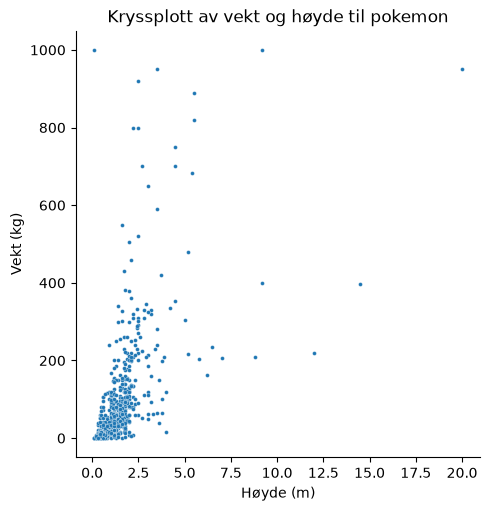

In [192]:
sns.relplot(x = 'height_m', y = 'weight_kg', kind = 'scatter', s = 8, data = pokedex)
plt.xlabel("Høyde (m)")
plt.ylabel("Vekt (kg)")
plt.title("Kryssplott av vekt og høyde til pokemon")
plt.show()

In [193]:
forrige = pokedex[["id", "name", "height_m", "weight_kg"]]
pairs = pokedex.merge(forrige, left_on="evolves_from_id", right_on="id", suffixes=("", "_prev"))

pairs["log_h_ratio"] = np.log(pairs["height_m"] / pairs["height_m_prev"])
pairs["log_w_ratio"] = np.log(pairs["weight_kg"] / pairs["weight_kg_prev"])
pairs["normal"] = ((pairs["type1"] == "normal") | (pairs["type2"] == "normal")).astype(int)

print("Antall evolusjoner:", len(pairs), "| Normal-type:", pairs["normal"].sum())
pairs[["name_prev", "name", "log_h_ratio", "log_w_ratio", "normal"]].head()

Antall evolusjoner: 484 | Normal-type: 58


,name_prev,name,log_h_ratio,log_w_ratio,normal
0,bulbasaur,ivysaur,0.356675,0.633428,0
1,ivysaur,venusaur,0.693147,2.040221,0
2,charmander,charmeleon,0.606136,0.804373,0
3,charmeleon,charizard,0.435318,1.560911,0
4,squirtle,wartortle,0.693147,0.916291,0


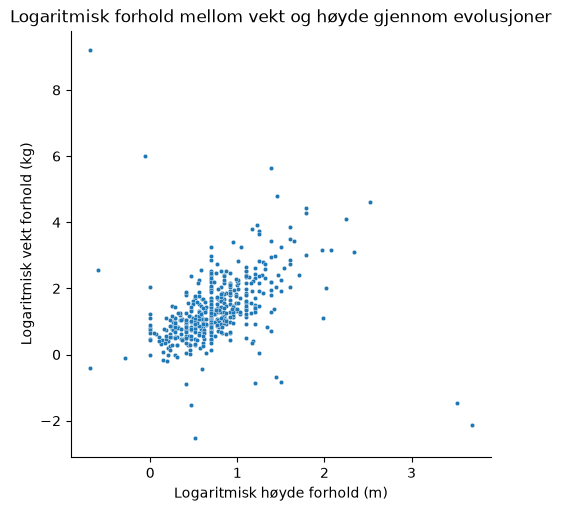

In [194]:
# plotter høyde forhold og vekt forhol mellom generasjoner 
sns.relplot(x = 'log_h_ratio', y = 'log_w_ratio', kind = 'scatter', s = 10, data = pairs)
plt.xlabel("Logaritmisk høyde forhold (m)")
plt.ylabel("Logaritmisk vekt forhold (kg)")
plt.title("Logaritmisk forhold mellom vekt og høyde gjennom evolusjoner")
plt.show()

In [195]:
formel = 'log_w_ratio ~ log_h_ratio'

modell = smf.ols(formel, data=pairs)
resultat = modell.fit()

print(resultat.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     60.18
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.20e-14
Time:                        11:41:06   Log-Likelihood:                -662.84
No. Observations:                 484   AIC:                             1330.
Df Residuals:                     482   BIC:                             1338.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.7890      0.084      9.402      

Det er flere ting i modellen som gjør at vi må forkaste hypotesen. 
H0: B1 = 3, H1: B1 != 3

Slik vi ser er det estimerte stigningstallet B1 = 0.74, som er langt unna hva kube-kvadrat-loven tilsier på en verdi av 3.
Vi finner heller ikke 3 i konfidensintervallet [0.55, 0.93]. 

Så dette betyr at vekten øker langt mindre med høyden enn hva kvadrat-kube-loven tilsier.

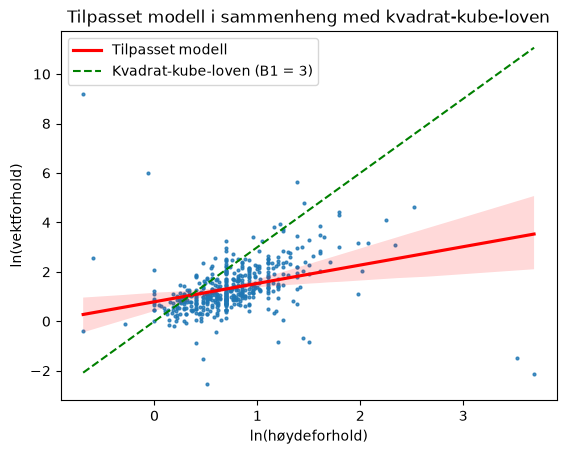

In [196]:
sns.regplot(x="log_h_ratio", y="log_w_ratio", data=pairs, line_kws={"color": "red", "label": "Tilpasset modell"}, scatter_kws={"s": 4})
x = np.linspace(pairs["log_h_ratio"].min(), pairs["log_h_ratio"].max(), 100)

plt.plot(x, 3 * x, color = "green", linestyle = "--", label = "Kvadrat-kube-loven (B1 = 3)")
plt.xlabel("ln(høydeforhold)")
plt.ylabel("ln(vektforhold)")
plt.title("Tilpasset modell i sammenheng med kvadrat-kube-loven")
plt.legend()
plt.show()

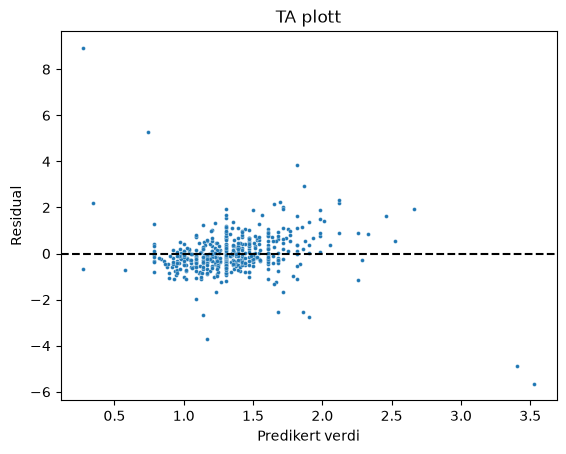

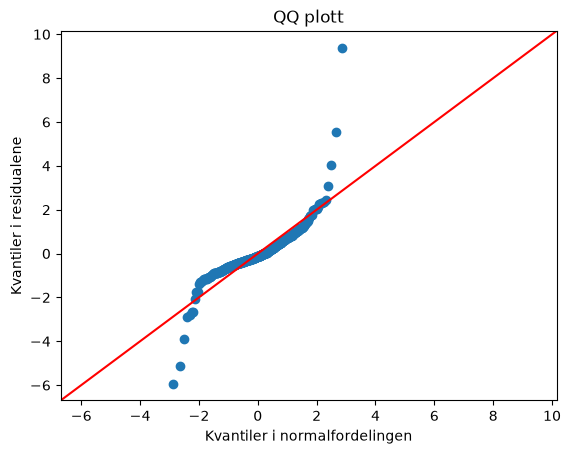

In [197]:
sns.scatterplot(x=resultat.fittedvalues, y=resultat.resid, s=8)
plt.xlabel("Predikert verdi")
plt.ylabel("Residual")
plt.axhline(0, color="black", linestyle="--")
plt.title("TA plott")
plt.show()

sm.qqplot(resultat.resid, line="45", fit=True)
plt.ylabel("Kvantiler i residualene")
plt.xlabel("Kvantiler i normalfordelingen")
plt.title("QQ plott")
plt.show()

In [198]:
pairs.loc[resultat.resid.abs().nlargest(5).index, ["name_prev", "name", "log_h_ratio", "log_w_ratio"]]

,name_prev,name,log_h_ratio,log_w_ratio
383,cosmog,cosmoem,-0.693147,9.210240
385,cosmoem,lunala,3.688879,-2.120164
56,haunter,gengar,-0.064539,6.003887
384,cosmoem,solgaleo,3.526361,-1.469576
455,tadbulb,bellibolt,1.386294,5.643679


Her ser du de fem største uteliggerne fra datasettet.

In [199]:
resultat2 = smf.ols("log_w_ratio ~ log_h_ratio * normal", data=pairs).fit()
print(resultat2.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     23.16
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.11e-14
Time:                        11:41:07   Log-Likelihood:                -658.60
No. Observations:                 484   AIC:                             1325.
Df Residuals:                     480   BIC:                             1342.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.8548      0

Slik vi ser her har pokemon av normal type mindre avvik fra loven, selv om den er langt unna 3. 
Dette kan vi da bruke i klassifiseringen for å løse hypotese 2. 

Hypotese 3 vil forutsette at stigningstallet B1 vil være nærmere 3 for tidlige generasjoner av pokemon.

In [200]:
pairs["gen"] = pairs["generation"].astype(int)
print(pairs["gen"].value_counts().sort_index())

gen
1    83
2    46
3    62
4    55
5    74
6    35
7    33
8    48
9    48
Name: count, dtype: int64


   gen   n  beta1  nedre  øvre
0    1  83   1.09   0.58  1.61
1    2  46   1.03   0.69  1.38
2    3  62   0.61   0.10  1.13
3    4  55   1.13   0.62  1.63
4    5  74   1.54   1.23  1.84
5    6  35   1.19   0.54  1.84
6    7  33  -0.66  -1.43  0.11
7    8  48   1.42   0.71  2.13
8    9  48   1.44   0.88  2.00


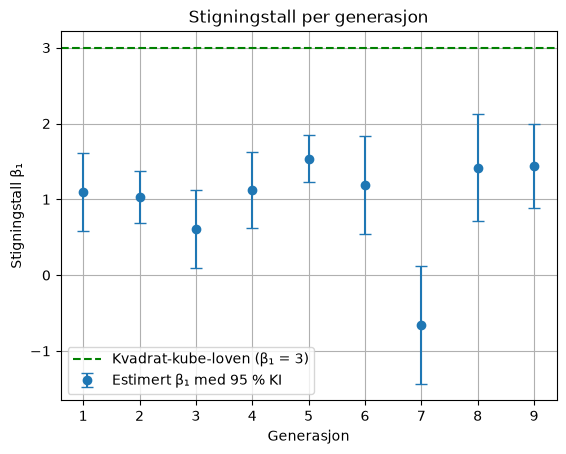

In [201]:
rader = []
for g, data_g in pairs.groupby("gen"):
    res_g = smf.ols("log_w_ratio ~ log_h_ratio", data=data_g).fit()
    ki = res_g.conf_int().loc["log_h_ratio"]
    rader.append({"gen": g, "n": len(data_g), "beta1": res_g.params["log_h_ratio"], "nedre": ki[0], "øvre": ki[1]})
per_gen = pd.DataFrame(rader)
print(per_gen.round(2))

plt.errorbar(per_gen["gen"], per_gen["beta1"], yerr=[per_gen["beta1"] - per_gen["nedre"], per_gen["øvre"] - per_gen["beta1"]], fmt="o", capsize=4, label="Estimert β₁ med 95 % KI")
plt.axhline(3, color="green", linestyle="--", label="Kvadrat-kube-loven (β₁ = 3)")
plt.xlabel("Generasjon")
plt.ylabel("Stigningstall β₁")
plt.title("Stigningstall per generasjon")
plt.legend()
plt.grid()
plt.show()

Her er det mye å diskutere. Vi kan faktisk se hvordan grafen stiger for senere generasjoner. Det er også noe som skjedde ved generasjon 7 som er med på å endre resultatet, ettersom at stigingstallet burde bli positivt slik vi ser ut fra grafen. 

In [202]:
resultat3 = smf.ols("log_w_ratio ~ log_h_ratio * gen", data=pairs).fit()
print(resultat3.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     22.17
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.84e-13
Time:                        11:41:07   Log-Likelihood:                -659.91
No. Observations:                 484   AIC:                             1328.
Df Residuals:                     480   BIC:                             1345.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.4507      0.171     

I tilfellet hvor vi inkluderer alle pokemon får vi riktig fortegn som stemmer overrens med hypotesen. 
Man kan også se at p-verdien er større en 5% og utenfor konfidensintervallet, så det er mange tilfeldigheter i dataen. 
For å sjekke om dette bare er en feil så fjerner vi den største uteliggeren cosmoem.

In [203]:
uten_cosmog = pairs[~pairs["name_prev"].isin(["cosmog", "cosmoem"])]
resultat3b = smf.ols("log_w_ratio ~ log_h_ratio * gen", data=uten_cosmog).fit()
print(resultat3b.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.332
Model:                            OLS   Adj. R-squared:                  0.328
Method:                 Least Squares   F-statistic:                     79.11
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.50e-41
Time:                        11:41:07   Log-Likelihood:                -547.79
No. Observations:                 481   AIC:                             1104.
Df Residuals:                     477   BIC:                             1120.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.6085      0.137     

Slik vi ser, følger faktsik nyere generasjoner kvadrat-kube-loven bedre enn hva tidligere generasjoner gjør. Dersom vi fjerner den største uteliggeren vil vi få et positivt fortegn i stigningstallet. Hypotese 3 er derfor ikke sann. 